# Billboard-only baselines — Grammy Stage 1, 2 and 3

**Prepared without executing the notebook or fitting any model.** Run All in Kaggle; CPU is sufficient and GPU T4 is optional. No MCMC or additional package installation is needed.

This notebook answers the instructor's question: does the multifeature Bayesian pipeline improve on a simple chart-popularity model? The baseline uses Billboard exposure only. Original reference data are compressed inside the notebook, so **no input ZIP is required**. Optional paths below allow a newer artist CSV, matching Stage1 Bayesian predictions, and the saved Stage2/3 Bayesian results ZIP/directory.

Default backtests are seasons 2024 and 2025 (ceremonies 2025 and 2026). Forecast season 2026 means ceremony 2027. The embedded Stage1 probabilities are explicitly the original-data v4 reference, not a claim about your most recent run.

In [56]:
from pathlib import Path
import json, zipfile, io, base64, hashlib, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy.optimize import minimize, minimize_scalar
from scipy.special import expit, logsumexp
from IPython.display import display, FileLink
import matplotlib.pyplot as plt
SEED=20261101
TEST_SEASONS=[2024,2025]
FORECAST_SEASON=2026
SIMULATIONS=20000
CATEGORIES=['album_of_the_year','record_of_the_year','song_of_the_year','best_new_artist','pop_vocal_album','pop_solo','pop_duo_group','music_video']
ALBUM_CATS={'album_of_the_year','pop_vocal_album'}
# Optional: point to newer data/exports if you want to replace the embedded reference snapshot.
ARTIST_CSV_PATH = ''
BAYES_STAGE1_PRED_PATH = ''  # CSV backtest_predictions.csv from the matching Stage1 run
BAYES_STAGE23_RESULTS_PATH = ''  # ZIP or directory from your Bayesian Stage2/3 run
ROOT=Path('/kaggle/working') if Path('/kaggle').exists() else Path.cwd()
OUTPUT=ROOT/'billboard_baseline_results'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
OUTPUT.mkdir(parents=True,exist_ok=True)
MODEL_VERSION='billboard-only-constrained-mle-v1'

## Input snapshot

Embedded data: artist-season-category chart weeks and nomination labels, audited historical work/event outcomes, frozen forecast work choices, and Stage1 held-out Bayesian probabilities. All inputs have SHA256 fingerprints. Future nomination and winner labels are not used.

If `ARTIST_CSV_PATH` is set, that CSV must contain `season, cat, artist_key, artist, h_weeks, b_weeks, nominated`. A nomination comparison is performed only when the Bayesian reference has identical test pools and labels. With changed data, supply the matching `backtest_predictions.csv` via `BAYES_STAGE1_PRED_PATH`. Historical work identities and the incomplete forecast catalog retain the documented project limitations.

In [57]:
# Embedded, compressed data reference: no input upload or ZIP path is needed.
EMBEDDED_DATA = '...'
EMBEDDED_HASHES = {'artists.csv': '40983a1ea1b2422076c523c4003b602f73b4ab9ec2b56372baedfcf327f3a45c', 'history.csv': '597ef9450e48415bbebbad86a5579459f105faa03bfa670878ab32a212da726b', 'choices.csv': 'a90001ad1b28835c5bc2f7c247ed6580fe94e9b66016d7ce221cb01d2b09b695', 'bayes1.csv': '236a1b0b25d3e2d1768d58a440b2dd4c32837dc54305e37b848d92271ab162a3'}
with zipfile.ZipFile(io.BytesIO(base64.b64decode(EMBEDDED_DATA))) as z:
    payload={n:z.read(n) for n in EMBEDDED_HASHES}
for n,b in payload.items():
    if hashlib.sha256(b).hexdigest()!=EMBEDDED_HASHES[n]:raise ValueError('Embedded data hash mismatch')
artists=pd.read_csv(ARTIST_CSV_PATH) if ARTIST_CSV_PATH else pd.read_csv(io.BytesIO(payload['artists.csv']))
artists=artists[['season','cat','artist_key','artist','h_weeks','b_weeks','nominated']].copy()
if artists.duplicated(['season','cat','artist_key']).any():raise ValueError('Duplicate artist keys')
if (artists[['h_weeks','b_weeks']]<0).any().any():raise ValueError('Negative chart exposure')
history=pd.read_csv(io.BytesIO(payload['history.csv']))
choices=pd.read_csv(io.BytesIO(payload['choices.csv']))
bayes1=pd.read_csv(io.BytesIO(payload['bayes1.csv']))
for f in [history,choices]:f['artist_keys']=f.artist_keys.map(json.loads)
if not history.groupby('event_id').winner.sum().eq(1).all():raise ValueError('Invalid original-event outcomes')
if choices.duplicated(['season','cat','work_id']).any():raise ValueError('Duplicate work choices')
if choices[choices.season.eq(FORECAST_SEASON)].winner.notna().any():raise ValueError('Future winner labels must be absent')
names=dict(zip(artists.artist_key,artists.artist))
for r in choices.itertuples():names.update(zip(r.artist_keys,json.loads(r.all_performers)))
def artist_name(k):return names.get(k,k)
print('Embedded data loaded; seasons 2024/2025 refer to ceremonies 2025/2026.')
print('Artist rows:',len(artists),'historical events:',history.event_id.nunique())
print('Output:',OUTPUT)

Embedded data loaded; seasons 2024/2025 refer to ceremonies 2025/2026.
Artist rows: 203944 historical events: 230
Output: /kaggle/working/billboard_baseline_results/20261101T160844022751


## Stage 1: chart-only nomination baseline

Score: standardized log(1 + Billboard 200 weeks) in album categories; standardized log(1 + Hot100 weeks) in recording, song, solo, duo/group and video categories. For Best New Artist, take the mean of the standardized Hot100 and Billboard200 scores. All medians, means and scales use the training fold only.

For each category, fit `P(nominated)=sigmoid(alpha + lambda * score)` by ordinary maximum likelihood, with `lambda >= 0`. There are just an intercept and one popularity slope per category. No class weighting or resampling changes the probability target. The nonnegative slope makes this a popularity rule; if the optimum is zero, top-five ties are broken by chart score, then artist key. The uniform reference uses the training nomination rate and its precision@5 is the analytical expected hit rate of a random five, not an arbitrary alphabetical selection.

Train on seasons strictly before each test season. Report Brier score and precision@5 by category/year, and the actual nominees alongside the predicted top five. Bayesian reference metrics use exactly the aligned test labels and pools. This comparison tests additional features plus estimation, not the isolated effect of Bayesian inference.

In [58]:
# Univariate probability model, estimated separately for each nomination category.
# Binary outcomes are never class-reweighted or resampled, preserving the probability target.
def bb_scaler(train):
    out={}
    for col in ['h_weeks','b_weeks']:
        x=np.log1p(train[col].to_numpy(float))
        med=float(np.nanmedian(x));x=np.where(np.isfinite(x),x,med)
        if not np.isfinite(med):raise ValueError(f'All values missing: {col}')
        sd=float(x.std());out[col]=(med,float(x.mean()),sd if sd>1e-10 else 1.)
    return out

def bb_scores(frame,cat,scaler):
    vals={}
    for col,(med,mu,sd) in scaler.items():
        x=np.log1p(frame[col].to_numpy(float));vals[col]=(np.where(np.isfinite(x),x,med)-mu)/sd
    if cat in ALBUM_CATS:return vals['b_weeks']
    if cat=='best_new_artist':return (vals['h_weeks']+vals['b_weeks'])/2
    return vals['h_weeks']

def fit_binary(z,y):
    # Nonnegative slope defines a popularity baseline. Intercept is unrestricted.
    y=np.asarray(y,float)
    if not np.isin(y,[0,1]).all() or len(np.unique(y))<2:raise ValueError('Need both nomination outcomes in training')
    rate=y.mean();initial=np.array([np.log(rate/(1-rate)),.1])
    def fun(t):
        eta=t[0]+t[1]*z
        return np.logaddexp(0,eta).sum()-y@eta
    def jac(t):
        err=expit(t[0]+t[1]*z)-y
        return np.array([err.sum(),err@z])
    fit=minimize(fun,initial,jac=jac,method='L-BFGS-B',bounds=[(None,None),(0,None)],options={'maxiter':3000,'ftol':1e-12,'gtol':1e-7})
    if not fit.success or not np.isfinite(fit.fun):raise RuntimeError(f'Nomination MLE failed: {fit.message}')
    if np.max(np.abs(fit.x))>1e4:raise RuntimeError('Possible separation: unstable unpenalized nomination MLE')
    return fit.x,dict(success=bool(fit.success),message=str(fit.message),iterations=int(fit.nit),training_log_likelihood=float(-fit.fun))

s1_predictions=[];s1_scores=[];s1_coefficients=[];s1_examples=[]
for season in [*TEST_SEASONS,FORECAST_SEASON]:
    for cat in CATEGORIES:
        tr=artists[artists.season.lt(season)&artists['cat'].eq(cat)].copy()
        te=artists[artists.season.eq(season)&artists['cat'].eq(cat)].copy()
        if len(te)<5:raise ValueError(f'Fewer than five artist candidates: {season}, {cat}')
        scaler=bb_scaler(tr);zt=bb_scores(tr,cat,scaler);z=bb_scores(te,cat,scaler)
        coef,diag=fit_binary(zt,tr.nominated.to_numpy())
        te['p_billboard']=expit(coef[0]+coef[1]*z);te['billboard_score']=z
        # If the constrained slope equals zero, use Billboard score to break probability ties.
        te=te.sort_values(['p_billboard','billboard_score','artist_key'],ascending=[False,False,True])
        te['rank_billboard']=np.arange(1,len(te)+1);te['p_uniform']=tr.nominated.mean()
        # Forecast-season labels stay missing even if a supplied file accidentally contains values.
        if season==FORECAST_SEASON:te['nominated']=np.nan
        s1_predictions.append(te[['season','cat','artist_key','artist','nominated','p_billboard','billboard_score','rank_billboard','p_uniform']])
        s1_coefficients.append(dict(season=season,cat=cat,intercept=coef[0],slope=coef[1],scaler=json.dumps(scaler),**diag))
        if season in TEST_SEASONS:
            y=te.nominated.to_numpy(float)
            if not np.isin(y,[0,1]).all():raise ValueError('Historical nomination labels missing')
            s1_scores.extend([dict(season=season,cat=cat,model='billboard_logit',brier=float(np.mean((te.p_billboard-y)**2)),precision_at_5=float(te.head(5).nominated.mean())),dict(season=season,cat=cat,model='uniform_reference',brier=float(np.mean((te.p_uniform-y)**2)),precision_at_5=float(y.mean()))])
            predicted=te.head(5).copy();predicted['row_type']='predicted_top5'
            actual=te[te.nominated.eq(1)].copy();actual['row_type']='actual_nominee'
            s1_examples.extend([predicted,actual])
s1=pd.concat(s1_predictions,ignore_index=True)
s1.to_csv(OUTPUT/'stage1_billboard_predictions.csv',index=False)
pd.DataFrame(s1_coefficients).to_csv(OUTPUT/'stage1_mle_coefficients.csv',index=False)
# Bayesian reference probabilities must have exactly matching pools and labels.
bp=bayes1.copy()
if BAYES_STAGE1_PRED_PATH:bp=pd.read_csv(BAYES_STAGE1_PRED_PATH)
comparison=s1[s1.season.isin(TEST_SEASONS)].merge(bp[['season','cat','artist_key','nominated','p_probit']],on=['season','cat','artist_key'],suffixes=('_bb','_bayes'),how='outer',indicator=True,validate='one_to_one')
matched=bool(comparison['_merge'].eq('both').all() and comparison.nominated_bb.eq(comparison.nominated_bayes).all())
if matched:
    for (season,cat),g in comparison.groupby(['season','cat']):
        top=g.sort_values(['p_probit','artist_key'],ascending=[False,True]).head(5)
        s1_scores.append(dict(season=season,cat=cat,model='bayesian_probit_reference',brier=float(np.mean((g.p_probit-g.nominated_bb)**2)),precision_at_5=float(top.nominated_bb.mean())))
else:
    print('Bayesian Stage1 comparison skipped: pools or labels differ. Baseline results are still exported.')
    comparison.to_csv(OUTPUT/'stage1_comparison_alignment.csv',index=False)
s1_metrics=pd.DataFrame(s1_scores);s1_metrics.to_csv(OUTPUT/'stage1_backtest_metrics.csv',index=False)
pd.concat(s1_examples,ignore_index=True).to_csv(OUTPUT/'PRESENTATION_stage1_predictions_vs_actual.csv',index=False)
print('Stage1 backtests; lower Brier and higher precision@5 are better:')
display(s1_metrics.groupby('model')[['brier','precision_at_5']].mean())
display(s1[s1.season.eq(FORECAST_SEASON)&s1.rank_billboard.le(5)][['cat','artist','p_billboard']])

Stage1 backtests; lower Brier and higher precision@5 are better:


,brier,precision_at_5
model,,
bayesian_probit_reference,0.007557,0.587500
billboard_logit,0.009852,0.237500
uniform_reference,0.010766,0.010869


,cat,artist,p_billboard
10512,album_of_the_year,Drake,0.211131
10513,album_of_the_year,Taylor Swift,0.187078
10514,album_of_the_year,The Weeknd,0.112425
10515,album_of_the_year,Morgan Wallen,0.099050
10516,album_of_the_year,Zach Bryan,0.090216
11150,record_of_the_year,Ella Langley,0.256353
11151,record_of_the_year,Drake,0.242764
11152,record_of_the_year,Taylor Swift,0.214684
11153,record_of_the_year,Olivia Dean,0.211368
11154,record_of_the_year,Morgan Wallen,0.191156


## Stage 2: chart-only winner baseline

Hold the original Stage1-derived WORK sets fixed to compare Stage2 models on identical alternatives. Do not regenerate those sets from the Billboard Stage1 rankings: that would combine nomination and winner-model changes. Billboard Stage1 top fives are exported separately.

For a work, calculate mean Hot100/Billboard200 weeks of its named performers, then the same category-specific log/standardization rule. Missing artist exposure is imputed from the training work pool; absence is not silently interpreted as zero exposure. Fit a pooled scalar `lambda >= 0` with `P(work j wins | set)=softmax(lambda * score_j)`. There is one categorical outcome per original historical event. An event intercept cancels. The likelihood fit is ordinary MLE, with no Bayesian prior. An expanding numerical bracket detects a potentially unbounded estimate instead of silently fixing it at a cap.

The baseline uses **1/K** when lambda=0. K is the actual deduplicated choice-set size. Stage2 inputs are performer-level exposure proxies; this does not claim track-specific Billboard modeling.

In [59]:
# Fair Stage2 comparison freezes the SAME original Stage1 work choices for both models.
# Stage1 Billboard top-five forecasts above do not change these work sets.
snap=artists.set_index(['season','cat','artist_key'])
def work_exposure(frame):
    rows=[]
    for r in frame.itertuples():
        found=[snap.loc[(r.season,r.cat,a),['h_weeks','b_weeks']].to_numpy(float) for a in r.artist_keys if (r.season,r.cat,a) in snap.index]
        rows.append(np.mean(found,axis=0) if found else [np.nan,np.nan])
    v=pd.DataFrame(rows,columns=['h_weeks','b_weeks'])
    return v.assign(cat=frame['cat'].to_numpy())
HX=work_exposure(history);CX=work_exposure(choices)
def work_scalers(frame,exposure):
    return {cat:bb_scaler(exposure.loc[frame['cat'].eq(cat).to_numpy()]) for cat in CATEGORIES}
def work_z(frame,exposure,scalers):
    z=np.empty(len(frame))
    for cat in CATEGORIES:
        m=frame['cat'].eq(cat).to_numpy()
        z[m]=bb_scores(exposure.loc[m],cat,scalers[cat])
    return z

def fit_temperature(frame,z):
    groups=[g.index.to_numpy() for _,g in frame.groupby('event_id')]
    winners=[]
    for idx in groups:
        hit=np.flatnonzero(frame.iloc[idx].winner.to_numpy()==1)
        if len(hit)!=1:raise ValueError('Each original event must have one winner')
        winners.append(idx[hit[0]])
    def nll(lam):return sum(logsumexp(lam*z[idx])-lam*z[w] for idx,w in zip(groups,winners))
    # The only coefficient is constrained to be nonnegative. Expand a numerical search
    # bracket until the optimum is interior; do not silently truncate separation at a cap.
    upper=2.
    for _ in range(16):
        opt=minimize_scalar(nll,bounds=(0,upper),method='bounded',options={'xatol':1e-9})
        if not opt.success:raise RuntimeError('Stage2 likelihood optimization failed')
        if opt.x<upper*.98:break
        upper*=2
    else:raise RuntimeError('Stage2 MLE may be unbounded; do not interpret a truncated fit')
    lam=0. if nll(0.)<=opt.fun+1e-9 else float(opt.x)
    return lam,dict(slope=lam,training_log_likelihood=float(-nll(lam)),training_events=len(groups),search_upper=upper)

def predict_work(frame,z,lam):
    pred={}
    for e,g in frame.groupby('event_id',sort=True):
        idx=frame.index.get_indexer(g.index);eta=lam*z[idx]
        pred[e]={'frame':g.reset_index(drop=True),'logp':(eta-logsumexp(eta))[None,:]}
    return pred

def actual_counts(frame):
    result={}
    for r in frame[frame.winner.eq(1)].itertuples():
        for a in set(r.artist_keys):result[a]=result.get(a,0)+1
    return result

def score_stage2(pred,season,model,protocol):
    scores=[];probs=[];examples=[]
    actual=history[history.season.eq(season)&history.winner.eq(1)] if season in TEST_SEASONS else None
    for o in pred.values():
        g=o['frame'];lp=o['logp'][0];hit=np.flatnonzero(g.winner.to_numpy()==1)
        covered=len(hit)==1;cat=g['cat'].iloc[0]
        scores.append(dict(season=season,cat=cat,model=model,protocol=protocol,K=len(g),winner_covered=covered if actual is not None else None,log_score=float(lp[hit[0]]) if covered else np.nan,negative_log_loss=float(-lp[hit[0]]) if covered else np.nan))
        for j,r in enumerate(g.itertuples()):
            probs.append(dict(season=season,ceremony_year=season+1,cat=cat,model=model,protocol=protocol,work_id=r.work_id,title=r.title,performer=r.performer,artist_keys=json.dumps(r.artist_keys),probability=float(np.exp(lp[j])),winner=r.winner))
        j=int(np.argmax(lp));r=g.iloc[j]
        if actual is not None:
            true=actual[actual['cat'].eq(cat)]
            examples.append(dict(season=season,ceremony_year=season+1,cat=cat,model=model,protocol=protocol,predicted_work=r.title,predicted_artist=r.performer,probability=float(np.exp(lp[j])),actual_work=' | '.join(true.title),actual_artist=' | '.join(true.performer),correct=bool(r.winner==1),winner_in_set=covered,top_probability_tied=int(np.isclose(lp,lp.max(),atol=1e-12,rtol=0).sum())>1))
    return scores,probs,examples

## Stage 3: predictive count distributions

Use Stage2 probabilities at the estimated coefficient. Draw one winning work in each category and give every named performing act on a shared work +1. Bands remain one act; this is the agreed project target across eight categories, not official songwriter/producer trophy accounting.

Compute marginal count PMFs by exact log-space recursion and save joint categorical simulations as well. Categories are independent conditional on the fitted probabilities. This frequentist plug-in baseline does not integrate coefficient estimation uncertainty. Compare it to the Bayesian posterior predictive distribution with that difference stated. Prediction sets collect the most probable counts until mass reaches at least 90%; they need not be contiguous.

In [60]:
def stage3(pred,model,season,actual=None):
    objects=list(pred.values())
    if len(objects)!=8 or {o['frame']['cat'].iloc[0] for o in objects}!=set(CATEGORIES): raise ValueError('Need eight category events')
    D=objects[0]['logp'].shape[0]
    if any(o['logp'].shape[0]!=D for o in objects): raise ValueError('Posterior draws must align across categories')
    acts=sorted(set(a for o in objects for z in o['frame'].artist_keys for a in z))
    pmfs=[];summaries=[]
    for a in acts:
        dp=np.full((D,9),-np.inf);dp[:,0]=0
        for i,o in enumerate(objects):
            hit=o['frame'].artist_keys.map(lambda z:a in z).to_numpy()
            ly=logsumexp(o['logp'][:,hit],axis=1) if hit.any() else np.full(D,-np.inf)
            ln=logsumexp(o['logp'][:,~hit],axis=1) if (~hit).any() else np.full(D,-np.inf)
            new=np.full_like(dp,-np.inf);new[:,:i+1]=dp[:,:i+1]+ln[:,None]
            new[:,1:i+2]=np.logaddexp(new[:,1:i+2],dp[:,:i+1]+ly[:,None]);dp=new
        logpmf=logsumexp(dp,axis=0)-np.log(D);p=np.exp(logpmf)
        if not np.isclose(p.sum(),1): raise ValueError('Count PMF does not normalize')
        selected=[];mass=0.
        for n in sorted(range(9),key=lambda n:(-p[n],n)):
            selected.append(n);mass+=p[n]
            if mass>=.9:break
        cdf=p.cumsum();obs=None if actual is None else actual.get(a,0)
        summaries.append(dict(season=int(season),ceremony_year=int(season)+1,model=model,artist_key=a,artist=artist_name(a),expected_awards=float(p@np.arange(9)),p_at_least_one=float(p[1:].sum()),p_at_least_two=float(p[2:].sum()),mode_count=int(p.argmax()),prediction_set_90=json.dumps(sorted(selected)),prediction_set_mass=mass,interval_q05=int(np.searchsorted(cdf,.05)),interval_q95=int(np.searchsorted(cdf,.95)),actual_count=obs,count_log_score=None if obs is None else float(logpmf[obs]),covered_90=None if obs is None else obs in selected))
        pmfs.extend(dict(season=int(season),model=model,artist_key=a,artist=artist_name(a),count=n,probability=p[n],log_probability=logpmf[n]) for n in range(9))
    rng=np.random.default_rng(SEED+int(season));draw=rng.integers(D,size=SIMULATIONS);sim=np.zeros((SIMULATIONS,len(acts)),np.int8);ai={a:i for i,a in enumerate(acts)}
    for o in objects:
        p=np.exp(o['logp'][draw]);cdf=p.cumsum(1);cdf[:,-1]=1
        winning=(rng.random(SIMULATIONS)[:,None]>cdf).sum(1)
        for j,keys in enumerate(o['frame'].artist_keys):
            for a in set(keys):sim[:,ai[a]]+=(winning==j)
    np.savez_compressed(OUTPUT/f'stage3_simulations_{model}_{season}.npz',counts=sim,artist_keys=np.asarray(acts),probability_vector_index=draw)
    return pd.DataFrame(pmfs),pd.DataFrame(summaries).sort_values(['expected_awards','artist_key'],ascending=[False,True])

## Run the backtests and final forecasts

Three small MLE fits for Stage2: two historical folds and one final fit. Task A evaluates among official nominees; Task B evaluates among the SAME frozen constructed sets used by the Bayesian notebook. Report Task B coverage separately and score only covered events for its conditional winner score. Stage3 Task B historical count scoring is permitted only when all eight winning works are covered; report the number of such ceremonies, including zero.

Unknown work dates and nomination/genre/submission eligibility gaps are inherited from the frozen catalog. Forecasts are conditional on the winner being in the constructed set (all eight sets for counts). Shared works appear once; credited artist win totals may exceed eight.

In [61]:
scores2=[];probabilities2=[];examples2=[];all_pmfs=[];all_counts=[];fit_records=[];coverage_rows=[]
for season in [*TEST_SEASONS,FORECAST_SEASON]:
    train_mask=history.season.lt(season).to_numpy()
    tr=history.loc[train_mask].reset_index(drop=True);xt=HX.loc[train_mask].reset_index(drop=True)
    scalers=work_scalers(tr,xt);lam,diag=fit_temperature(tr,work_z(tr,xt,scalers))
    fit_records.append(dict(season=season,scalers=json.dumps(scalers),**diag))
    cm=choices.season.eq(season).to_numpy();cand=choices.loc[cm].reset_index(drop=True);xc=CX.loc[cm].reset_index(drop=True)
    if set(cand['cat'])!=set(CATEGORIES):raise ValueError('Missing forecast categories')
    cov=cand.groupby('cat').winner.sum().reindex(CATEGORIES).eq(1) if season in TEST_SEASONS else None
    qualifies=bool(cov.all()) if cov is not None else None
    for cat in CATEGORIES:
        coverage_rows.append(dict(season=season,cat=cat,K=int(cand['cat'].eq(cat).sum()),winner_covered=None if cov is None else bool(cov[cat]),all_eight_covered=qualifies))
    tasks=[('B_constructed_shortlist',cand,xc)]
    if season in TEST_SEASONS:
        om=history.season.eq(season).to_numpy()
        tasks.append(('A_official_nominees',history.loc[om].reset_index(drop=True),HX.loc[om].reset_index(drop=True)))
    for protocol,frame,exposure in tasks:
        z=work_z(frame,exposure,scalers)
        for model,coef in [('billboard_logit',lam),('uniform_reference',0.)]:
            pred=predict_work(frame,z,coef)
            sc,pr,ex=score_stage2(pred,season,model,protocol);scores2+=sc;probabilities2+=pr;examples2+=ex
            actual=actual_counts(history[history.season.eq(season)]) if season in TEST_SEASONS and (protocol.startswith('A') or qualifies) else None
            pmf,cs=stage3(pred,model+'_'+protocol,season,actual=actual)
            for q in [pmf,cs]:q['model']=model;q['protocol']=protocol
            cs['all_eight_covered']=qualifies;all_pmfs.append(pmf);all_counts.append(cs)
score2=pd.DataFrame(scores2);prob2=pd.DataFrame(probabilities2);counts=pd.concat(all_counts,ignore_index=True);pmfs=pd.concat(all_pmfs,ignore_index=True)
for name,table in [('stage2_metrics',score2),('stage2_probabilities',prob2),('PRESENTATION_stage2_predictions_vs_actual',pd.DataFrame(examples2)),('stage3_count_summaries',counts),('stage3_count_pmf',pmfs),('stage2_fit_coefficients',pd.DataFrame(fit_records)),('shortlist_coverage',pd.DataFrame(coverage_rows))]:table.to_csv(OUTPUT/(name+'.csv'),index=False)
future=prob2[prob2.season.eq(FORECAST_SEASON)&prob2.model.eq('billboard_logit')]
future_top=future.sort_values(['cat','probability','work_id'],ascending=[True,False,True]).drop_duplicates('cat')
future_top.to_csv(OUTPUT/'PRESENTATION_stage2_winners_2027.csv',index=False)
future_counts=counts[counts.season.eq(FORECAST_SEASON)&counts.model.eq('billboard_logit')]
future_counts.to_csv(OUTPUT/'PRESENTATION_stage3_awards_2027.csv',index=False)
print('Stage2 historical log scores: higher is better; Task B scores condition on coverage.')
display(score2[score2.season.isin(TEST_SEASONS)].groupby(['protocol','model']).agg(mean_log_score=('log_score','mean'),scored_events=('log_score','count')))
print('Stage3 Task B qualifying ceremonies:');display(pd.DataFrame(coverage_rows).query('season in @TEST_SEASONS').groupby('season').all_eight_covered.first())
print('Billboard Stage2 forecast 2027:');display(future_top[['cat','title','performer','probability']])
print('Billboard Stage3 forecast 2027:');display(future_counts[['artist','expected_awards','p_at_least_one','prediction_set_90']].head(12))

Stage2 historical log scores: higher is better; Task B scores condition on coverage.


/tmp/ipykernel_49/3137592101.py:26: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  score2=pd.DataFrame(scores2);prob2=pd.DataFrame(probabilities2);counts=pd.concat(all_counts,ignore_index=True);pmfs=pd.concat(all_pmfs,ignore_index=True)


mean_log_score  scored_events
protocol                model                                           
A_official_nominees     billboard_logit         -1.846806             16
                        uniform_reference       -1.844440             16
B_constructed_shortlist billboard_logit         -1.336768              5
                        uniform_reference       -1.302943              5

Stage3 Task B qualifying ceremonies:


season
2024    False
2025    False
Name: all_eight_covered, dtype: object

Billboard Stage2 forecast 2027:


,cat,title,performer,probability
328,album_of_the_year,The Life of a Showgirl,Taylor Swift,0.290132
333,best_new_artist,Ella Langley,Ella Langley,0.227812
339,music_video,The Fate of Ophelia,Taylor Swift,0.270636
342,pop_duo_group,The Life of a Showgirl,Taylor Swift & Sabrina Carpenter,0.276697
348,pop_solo,The Fate of Ophelia,Taylor Swift,0.268998
350,pop_vocal_album,The Life of a Showgirl,Taylor Swift,0.282398
353,record_of_the_year,Choosin’ Texas,Ella Langley,0.206614
362,song_of_the_year,The Fate of Ophelia,Taylor Swift,0.213569


Billboard Stage3 forecast 2027:


,artist,expected_awards,p_at_least_one,prediction_set_90
166,Taylor Swift,2.211373,0.931927,"[0, 1, 2, 3, 4]"
167,Ariana Grande,1.232428,0.757114,"[0, 1, 2]"
168,Sabrina Carpenter,0.924377,0.651607,"[0, 1, 2]"
169,BTS,0.714492,0.558106,"[0, 1, 2]"
170,Olivia Dean,0.651412,0.520422,"[0, 1, 2]"
171,Lady Gaga,0.617569,0.499993,"[0, 1, 2]"
172,Olivia Rodrigo,0.503383,0.440175,"[0, 1]"
173,Ella Langley,0.434426,0.387357,"[0, 1]"
174,Bruno Mars,0.386620,0.349267,"[0, 1]"
175,Cynthia Erivo,0.242937,0.242937,"[0, 1]"


## Optional paired comparison with your Bayesian Stage2/3 results

Set `BAYES_STAGE23_RESULTS_PATH` to your existing `stage23_results.zip` or its unpacked directory. No Bayesian training is run. The code checks selected work IDs AND performer mappings, checks event K and coverage in historical score tables, and then exports paired log scores and expected-count comparisons. Keep protocols A/B separate. A positive Bayesian-minus-Billboard log-score difference favors Bayesian predictions; higher log score is better.

Without that path, the notebook still computes all baseline results and its Stage1 comparison with the embedded reference. After entering a path, rerun only this comparison cell and the export cell. Compare actual results honestly; with two test ceremonies, avoid significance claims based on independent category outcomes.

In [62]:
# Optional comparison with actual saved Bayesian outputs. We do not recreate Bayesian fits.
comparison_status='not_requested'
if BAYES_STAGE23_RESULTS_PATH:
    p=Path(BAYES_STAGE23_RESULTS_PATH)
    if p.is_file():
        ext=OUTPUT/'bayesian_inputs';ext.mkdir(exist_ok=True)
        with zipfile.ZipFile(p) as z:
            for n in z.namelist():
                if not (ext/n).resolve().is_relative_to(ext.resolve()):raise ValueError('Unsafe archive path')
            z.extractall(ext)
        roots=list(ext.rglob('used_work_choices.csv'))
    else:roots=list(p.rglob('used_work_choices.csv'))
    if len(roots)!=1:raise ValueError('Choose one Bayesian result directory/ZIP with used_work_choices.csv')
    br=roots[0].parent;used=pd.read_csv(roots[0])
    # At minimum the final model comparison must use identical alternatives and credits.
    canon=lambda f:{(int(r.season),r.cat,r.work_id,tuple(sorted(json.loads(r.artist_keys) if isinstance(r.artist_keys,str) else r.artist_keys))) for r in f.itertuples()}
    if canon(used)!=canon(choices):raise ValueError('Bayesian and Billboard choice sets differ; paired comparison would be invalid')
    for filename in ['stage2_work_probabilities_2027.csv','stage3_artist_counts_2027.csv','backtest_stage2_scores.csv','backtest_stage3_count_scores.csv']:
        path=br/filename
        if path.exists():
            table=pd.read_csv(path);table.to_csv(OUTPUT/('bayesian_'+filename),index=False)
    path=br/'stage2_work_probabilities_2027.csv'
    if path.exists():
        bay=pd.read_csv(path);bay=bay[bay.model.eq('bayesian')]
        paired=future.merge(bay[['cat','work_id','probability']],on=['cat','work_id'],suffixes=('_billboard','_bayesian'),validate='one_to_one',how='outer',indicator=True)
        if not paired['_merge'].eq('both').all():raise ValueError('Final Bayesian work probabilities do not cover identical choices')
        paired.to_csv(OUTPUT/'PRESENTATION_stage2_bayesian_vs_billboard_2027.csv',index=False)
    path=br/'backtest_stage2_scores.csv'
    if path.exists():
        bay=pd.read_csv(path);bay=bay[bay.model.eq('bayesian')].copy()
        if bay.duplicated(['season','cat','protocol']).any():raise ValueError('Duplicate Bayesian score rows')
        paired=score2[score2.model.eq('billboard_logit')&score2.season.isin(TEST_SEASONS)].merge(bay[['season','cat','protocol','K','winner_covered','log_score']],on=['season','cat','protocol'],suffixes=('_billboard','_bayesian'),validate='one_to_one')
        if len(paired)!=32 or not paired.K_billboard.eq(paired.K_bayesian).all() or not paired.winner_covered_billboard.eq(paired.winner_covered_bayesian).all():raise ValueError('Backtest coverage or event alignment differs')
        paired['bayesian_minus_billboard_log_score']=paired.log_score_bayesian-paired.log_score_billboard
        paired.to_csv(OUTPUT/'PRESENTATION_stage2_bayesian_vs_billboard.csv',index=False)
        display(paired.groupby('protocol')[['log_score_billboard','log_score_bayesian','bayesian_minus_billboard_log_score']].mean())
    path=br/'stage3_artist_counts_2027.csv'
    if path.exists():
        bay=pd.read_csv(path);bay=bay[bay.model.eq('bayesian')]
        paired=future_counts.merge(bay[['artist_key','expected_awards','p_at_least_one']],on='artist_key',suffixes=('_billboard','_bayesian'),validate='one_to_one')
        paired.to_csv(OUTPUT/'PRESENTATION_stage3_bayesian_vs_billboard_2027.csv',index=False)
    comparison_status='aligned_supplied_bayesian_outputs'
else:print('To compare Stage2/3 with Bayesian results, set BAYES_STAGE23_RESULTS_PATH in settings and rerun only this cell and the export cell.')

To compare Stage2/3 with Bayesian results, set BAYES_STAGE23_RESULTS_PATH in settings and rerun only this cell and the export cell.


## Figures and download

Download `billboard_baseline_results.zip` from the Kaggle Output panel. It contains Stage1 predictions, nomination matches and metrics; Stage2 probabilities, predicted-versus-actual winners and conditional scores; Stage3 PMFs, counts, prediction sets and simulations; coefficients, coverage and metadata. Optional paired Bayesian comparisons are included when supplied.

Useful files: `stage1_backtest_metrics.csv`, `PRESENTATION_stage1_predictions_vs_actual.csv`, `PRESENTATION_stage2_predictions_vs_actual.csv`, `PRESENTATION_stage2_bayesian_vs_billboard.csv` (optional), and the two 2027 presentation forecast tables. The old uniform reference is retained alongside the informative chart-only baseline.

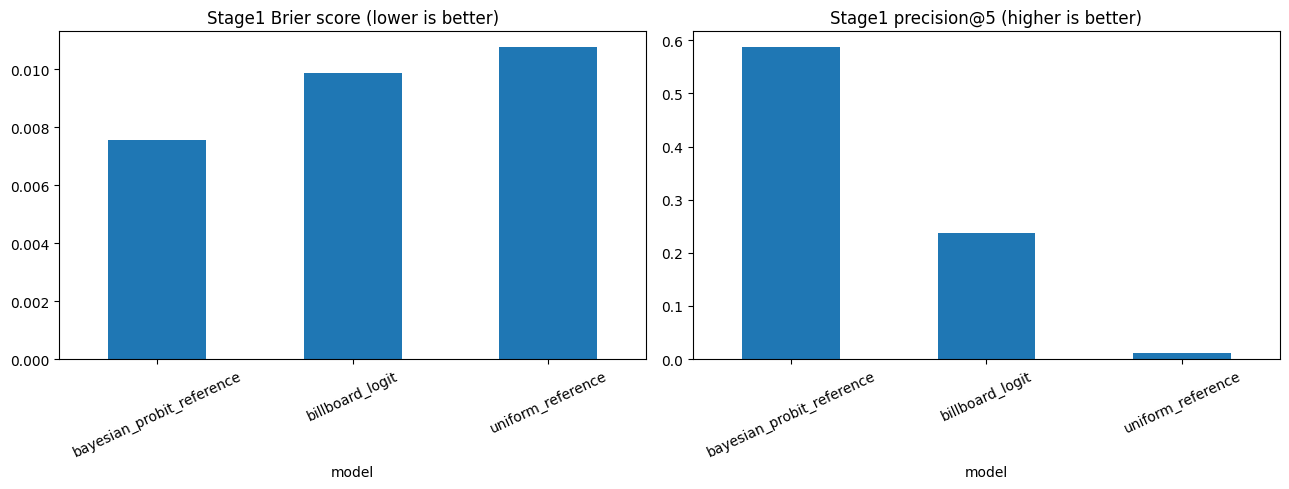

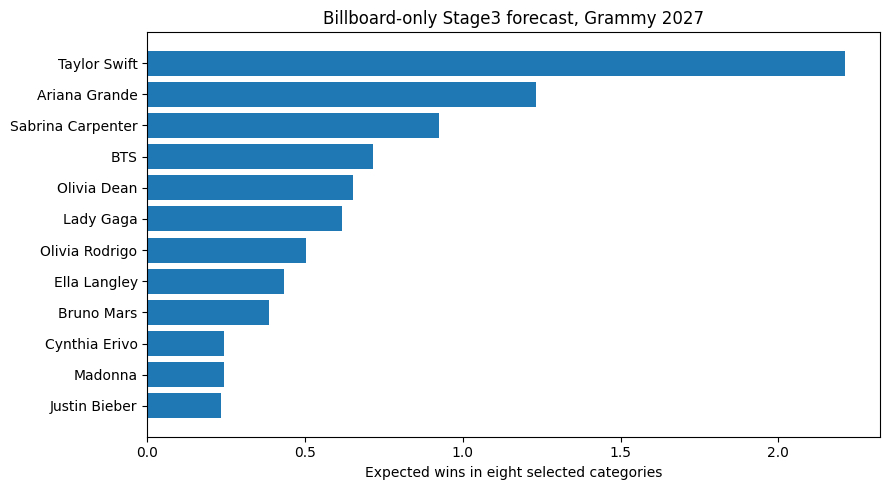

Download from Kaggle Output: /kaggle/working/billboard_baseline_results.zip


/kaggle/working/billboard_baseline_results.zip

In [63]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
m=s1_metrics.groupby('model')[['brier','precision_at_5']].mean()
m.brier.plot.bar(ax=axes[0],title='Stage1 Brier score (lower is better)',rot=25)
m.precision_at_5.plot.bar(ax=axes[1],title='Stage1 precision@5 (higher is better)',rot=25)
fig.tight_layout();fig.savefig(OUTPUT/'PRESENTATION_stage1_baseline_comparison.png',dpi=180,bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(9,5));top=future_counts.head(12).iloc[::-1]
ax.barh(top.artist,top.expected_awards);ax.set(xlabel='Expected wins in eight selected categories',title='Billboard-only Stage3 forecast, Grammy 2027');fig.tight_layout();fig.savefig(OUTPUT/'PRESENTATION_stage3_billboard_2027.png',dpi=180);plt.show()
metadata=dict(model_version=MODEL_VERSION,test_seasons=TEST_SEASONS,forecast_season=FORECAST_SEASON,source='embedded original reference snapshot' if not ARTIST_CSV_PATH else ARTIST_CSV_PATH,input_hashes=EMBEDDED_HASHES,stage1_bayesian_reference='embedded original-data v4' if not BAYES_STAGE1_PRED_PATH else BAYES_STAGE1_PRED_PATH,stage1_comparison_aligned=matched,stage23_comparison=comparison_status,stage1_predictors='one Billboard score; album B200, songs/video Hot100, BNA mean of standardized log1p H/B weeks',stage2_predictors='same score averaged over named performers, pooled nonnegative MLE slope',stage3='plug-in estimated probabilities; conditional category independence; shared-work credits; parameter uncertainty not integrated',conditioning='Stage2 TaskB winner in constructed set; Stage3 all eight winners in respective sets',limitations=['Stage2 work sets frozen to original Stage1 shortlist for a paired comparison, not regenerated from Billboard top5','Incomplete work catalog and album-availability proxies retained','Original Stage1 snapshot and identity limitations retained; date cutoff Sep30 proxy','Comparison to multifeature Bayesian models measures features plus estimation differences, not Bayesian inference alone','Only two test ceremonies; report each ceremony and avoid significance claims from independent-category assumptions'],versions=dict(numpy=np.__version__,pandas=pd.__version__,python=platform.python_version()))
(OUTPUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
archive=ROOT/'billboard_baseline_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT.rglob('*'):
        if p.is_file():z.write(p,p.relative_to(OUTPUT))
print('Download from Kaggle Output:',archive)
display(FileLink(str(archive)))

In [64]:
def run_expanded_billboard_backtests():
    global OUTPUT, TEST_SEASONS

    years = list(range(2018, 2026))
    old_output, old_test_seasons = OUTPUT, TEST_SEASONS
    out = ROOT / (
        "expanded_billboard_"
        + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%f")
    )
    out.mkdir(parents=True, exist_ok=True)

    s1_predictions, s1_scores, fit1_records = [], [], []
    s2_scores, s2_probabilities, s2_examples = [], [], []
    count_tables, pmf_tables, fit2_records = [], [], []

    try:
        OUTPUT = out
        TEST_SEASONS = years

        for season in years:
            print(f"Backtest season {season}, ceremony {season + 1}")

            for cat in CATEGORIES:
                tr = artists[
                    artists.season.lt(season) & artists["cat"].eq(cat)
                ].copy()
                te = artists[
                    artists.season.eq(season) & artists["cat"].eq(cat)
                ].copy()

                if len(te) < 5:
                    raise ValueError(f"Insufficient candidates: {season}, {cat}")
                if not te.nominated.isin([0, 1]).all():
                    raise ValueError(f"Invalid test labels: {season}, {cat}")

                scaler = bb_scaler(tr)
                z_train = bb_scores(tr, cat, scaler)
                z_test = bb_scores(te, cat, scaler)
                coef, diag = fit_binary(z_train, tr.nominated.to_numpy())

                te["p_billboard"] = expit(coef[0] + coef[1] * z_test)
                te["billboard_score"] = z_test
                te["p_uniform"] = float(tr.nominated.mean())
                te = te.sort_values(
                    ["p_billboard", "billboard_score", "artist_key"],
                    ascending=[False, False, True],
                )
                te["rank_billboard"] = np.arange(1, len(te) + 1)

                s1_predictions.append(te[[
                    "season", "cat", "artist_key", "artist", "nominated",
                    "p_billboard", "billboard_score",
                    "rank_billboard", "p_uniform",
                ]])

                y = te.nominated.to_numpy(float)
                for model, probability, precision in [
                    (
                        "billboard_logit",
                        te.p_billboard.to_numpy(),
                        float(te.head(5).nominated.mean()),
                    ),
                    (
                        "uniform_reference",
                        te.p_uniform.to_numpy(),
                        float(y.mean()),  # Expected random-five precision.
                    ),
                ]:
                    s1_scores.append(dict(
                        season=season, cat=cat, model=model,
                        n_candidates=len(te),
                        brier=float(np.mean((probability - y) ** 2)),
                        precision_at_5=precision,
                    ))

                fit1_records.append(dict(
                    season=season, cat=cat,
                    intercept=float(coef[0]), slope=float(coef[1]),
                    n_training=len(tr), scaler=json.dumps(scaler), **diag,
                ))

            tm = history.season.lt(season).to_numpy()
            vm = history.season.eq(season).to_numpy()
            tr = history.loc[tm].reset_index(drop=True)
            xt = HX.loc[tm].reset_index(drop=True)
            te = history.loc[vm].reset_index(drop=True)
            xv = HX.loc[vm].reset_index(drop=True)

            if (
                set(te["cat"]) != set(CATEGORIES)
                or te.groupby("cat").event_id.nunique().ne(1).any()
            ):
                raise ValueError(f"Expected eight category events: {season}")

            scalers = work_scalers(tr, xt)
            lam, diag = fit_temperature(tr, work_z(tr, xt, scalers))
            z_test = work_z(te, xv, scalers)
            fit2_records.append(dict(
                season=season, scalers=json.dumps(scalers), **diag,
            ))

            protocol = "A_official_nominees"
            observed_counts = actual_counts(te)

            for model, slope in [
                ("billboard_logit", lam),
                ("uniform_reference", 0.0),
            ]:
                pred = predict_work(te, z_test, slope)
                scores, probabilities, examples = score_stage2(
                    pred, season, model, protocol
                )

                # A tied maximum does not imply a genuine deterministic hit.
                # Expected hit = chance of winning under random tie-breaking.
                for obj in pred.values():
                    g = obj["frame"]
                    lp = obj["logp"][0]
                    tied = np.isclose(
                        lp, lp.max(), atol=1e-12, rtol=0
                    )
                    cat = g["cat"].iloc[0]
                    record = next(r for r in scores if r["cat"] == cat)
                    record["top1_expected_hit"] = float(
                        g.loc[tied, "winner"].mean()
                    )
                    record["n_tied_top"] = int(tied.sum())

                s2_scores.extend(scores)
                s2_probabilities.extend(probabilities)
                s2_examples.extend(examples)

                pmf, cs = stage3(
                    pred, model + "_" + protocol, season,
                    actual=observed_counts,
                )
                for table in (pmf, cs):
                    table["model"] = model
                    table["protocol"] = protocol

                cs["absolute_error"] = (
                    cs.expected_awards - cs.actual_count
                ).abs()
                count_tables.append(cs)
                pmf_tables.append(pmf)

    finally:
        OUTPUT = old_output
        TEST_SEASONS = old_test_seasons

    p1 = pd.concat(s1_predictions, ignore_index=True)
    m1 = pd.DataFrame(s1_scores)
    m2 = pd.DataFrame(s2_scores)
    c3 = pd.concat(count_tables, ignore_index=True)
    p3 = pd.concat(pmf_tables, ignore_index=True)

    if len(m1) != 128 or len(m2) != 128:
        raise ValueError("Expected 64 events per model for Stages 1 and 2.")

    p1.to_csv(out / "stage1_predictions_2018_2025.csv.gz", index=False)

    tables = {
        "stage1_scores_2018_2025": m1,
        "stage1_fit_coefficients": pd.DataFrame(fit1_records),
        "stage2_scores_2018_2025": m2,
        "stage2_work_probabilities_2018_2025":
            pd.DataFrame(s2_probabilities),
        "stage2_predictions_vs_actual": pd.DataFrame(s2_examples),
        "stage2_fit_coefficients": pd.DataFrame(fit2_records),
        "stage3_scores_2018_2025": c3,
        "stage3_pmfs_2018_2025": p3,
    }
    for name, table in tables.items():
        table.to_csv(out / f"{name}.csv", index=False)

    yearly1 = m1.groupby(["season", "model"])[
        ["brier", "precision_at_5"]
    ].mean().reset_index()
    yearly2 = m2.groupby(["season", "model"]).agg(
        negative_log_loss=("negative_log_loss", "mean"),
        top1_expected_hits=("top1_expected_hit", "sum"),
    ).reset_index()
    yearly3 = c3.groupby(["season", "model"]).agg(
        mean_count_log_score=("count_log_score", "mean"),
        mae_expected_count=("absolute_error", "mean"),
        coverage_90=("covered_90", "mean"),
    ).reset_index()

    for stage, table in [(1, yearly1), (2, yearly2), (3, yearly3)]:
        table.to_csv(out / f"stage{stage}_yearly_scores.csv", index=False)

    metadata = dict(
        model_version=MODEL_VERSION,
        experiment="expanded_billboard_backtest_2018_2025",
        test_seasons=years,
        ceremony_years=[s + 1 for s in years],
        training_rule="Use only seasons strictly earlier than test season",
        stage23_protocol="A_official_nominees",
        constructed_shortlists_evaluated=False,
        forecast_2027_modified=False,
        embedded_reference_hashes=EMBEDDED_HASHES,
        actual_artist_table_sha256=hashlib.sha256(
            artists.to_csv(index=False).encode()
        ).hexdigest(),
        limitations=[
            "Original labels, candidate-pool and identity limitations retained",
            "Stage3 uses plug-in probabilities without parameter uncertainty",
            "Top1 expected hits use random tie-breaking at tied maxima",
            "No end-to-end constructed-shortlist backtest for early seasons",
        ],
    )
    (out / "run_metadata.json").write_text(
        json.dumps(metadata, indent=2), encoding="utf-8"
    )

    print("\nStage 1: lower Brier / higher precision are better")
    display(m1.groupby("model")[["brier", "precision_at_5"]].mean())

    print("\nStage 2: official nominees; lower log loss is better")
    display(m2.groupby("model").agg(
        mean_log_loss=("negative_log_loss", "mean"),
        top1_expected_hits_out_of_64=("top1_expected_hit", "sum"),
    ))

    print("\nStage 3: higher log score / lower MAE are better")
    display(c3.groupby("model").agg(
        mean_count_log_score=("count_log_score", "mean"),
        mae_expected_count=("absolute_error", "mean"),
        coverage_90=("covered_90", "mean"),
    ))

    archive = ROOT / f"{out.name}.zip"
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
        for path in sorted(out.rglob("*")):
            if path.is_file():
                z.write(path, path.relative_to(out))

    print("\nDownload this ZIP:", archive)
    display(FileLink(str(archive)))
    return out


EXPANDED_BILLBOARD_OUTPUT = run_expanded_billboard_backtests()

Backtest season 2018, ceremony 2019
Backtest season 2019, ceremony 2020
Backtest season 2020, ceremony 2021
Backtest season 2021, ceremony 2022
Backtest season 2022, ceremony 2023
Backtest season 2023, ceremony 2024
Backtest season 2024, ceremony 2025
Backtest season 2025, ceremony 2026

Stage 1: lower Brier / higher precision are better


,brier,precision_at_5
model,,
billboard_logit,0.009243,0.175000
uniform_reference,0.009788,0.009875



Stage 2: official nominees; lower log loss is better


,mean_log_loss,top1_expected_hits_out_of_64
model,,
billboard_logit,1.894983,8.000000
uniform_reference,1.894243,9.952381



Stage 3: higher log score / lower MAE are better


,mean_count_log_score,mae_expected_count,coverage_90
model,,,
billboard_logit,-0.600795,0.371667,0.966292
uniform_reference,-0.594454,0.371888,0.973783



Download this ZIP: /kaggle/working/expanded_billboard_20261101T160906751101.zip


/kaggle/working/expanded_billboard_20261101T160906751101.zip